# 1. Data and exploratory analysis

**Business question.** Given a limited retention budget, which customers should receive an offer when both churn risk and expected economic value are considered? This notebook covers the first step: what the data contain, whether they are fit for the decision, and which customer segments differ in churn risk and value.

The notebook reads the artifacts of the current pipeline run (`python -m telco_retention run-all`); it fits nothing new. Numbers in the text were generated for run `20261029T034118630540Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
pd.set_option("display.precision", 3)
run = latest_run()
print("Run:", run.name)
customers = pd.read_csv(run / "customers.csv")
print(customers.shape)

Run: 20261029T034118630540Z-88be4b93
(7043, 23)


## Source and quality

The file is the IBM Telco Customer Churn sample (a fictional US company). It was downloaded once, its SHA-256 is checked on every run, and the raw file is never changed. The [source log](../docs/source-log.md) and [data readiness review](../docs/data-readiness-review.md) record the provenance and caveats.

In [2]:
source = read_json(run / "dataset_source.json")
quality = read_json(run / "data_quality.json")
display(pd.Series({k: source[k] for k in ["source", "downloaded_at_utc", "sha256", "rows"]}))
display(pd.Series({k: quality[k] for k in ["rows_before", "rows_after", "duplicates_removed", "total_charges_missing_before", "total_charges_filled_zero", "unique_ids"]}))

source                           Kaggle blastchar/telco-customer-churn
downloaded_at_utc                     2026-10-03T11:36:37.024155+00:00
sha256               88be4b93fbe0cc83421af1c503794c97c342eca914c157...
rows                                                              7043
dtype: object

rows_before                     7043
rows_after                      7043
duplicates_removed                 0
total_charges_missing_before      11
total_charges_filled_zero         11
unique_ids                      7043
dtype: int64

**Reading.** 11 blank `TotalCharges` belong to customers with zero tenure (not yet billed) and are set to 0; there are 0 duplicates and no other missing values. The data are clean; the limits are about meaning, not quality (single snapshot, fictional company, no offer data).

## Split used for every later step

In [3]:
display(customers.split.value_counts().rename("customers").to_frame().assign(churn_rate=customers.groupby("split").churn.mean()))

,customers,churn_rate
split,,
train,4225,0.265
validation,1409,0.265
test,1409,0.265


Churn is 26.5% overall and identical across splits (stratified). Exploration below uses **train only**, so no insight leaks from the data used for selection or reporting.

## Which segments churn most?

In [4]:
eda = pd.read_csv(run / "eda_segments.csv")
for attribute in ["Contract", "tenure_segment", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    display(eda.query("attribute == @attribute").sort_values("churn_rate", ascending=False)[["group", "n", "churn_rate", "mean_monthly_charges", "mean_tenure"]].set_index("group").rename_axis(attribute))

,n,churn_rate,mean_monthly_charges,mean_tenure
Contract,,,,
Month-to-month,2304,0.431,66.767,18.046
One year,896,0.110,65.028,41.955
Two year,1025,0.029,60.569,56.489


,n,churn_rate,mean_monthly_charges,mean_tenure
tenure_segment,,,,
new,1318,0.477,56.492,4.810
developing,615,0.278,60.427,18.250
loyal,2292,0.140,70.925,52.141


,n,churn_rate,mean_monthly_charges,mean_tenure
InternetService,,,,
Fiber optic,1859,0.419,91.875,33.258
DSL,1436,0.191,58.310,32.803
No,930,0.073,21.129,30.257


,n,churn_rate,mean_monthly_charges,mean_tenure
PaymentMethod,,,,
Electronic check,1410,0.456,76.550,25.566
Mailed check,967,0.196,44.224,21.807
Bank transfer (automatic),933,0.162,67.555,43.548
Credit card (automatic),915,0.150,66.066,42.957


,n,churn_rate,mean_monthly_charges,mean_tenure
TechSupport,,,,
No,2040,0.424,75.054,25.784
Yes,1255,0.150,80.811,44.886
No internet service,930,0.073,21.129,30.257


,n,churn_rate,mean_monthly_charges,mean_tenure
SeniorCitizen,,,,
1,682,0.413,79.653,32.949
0,3543,0.237,62.054,32.345


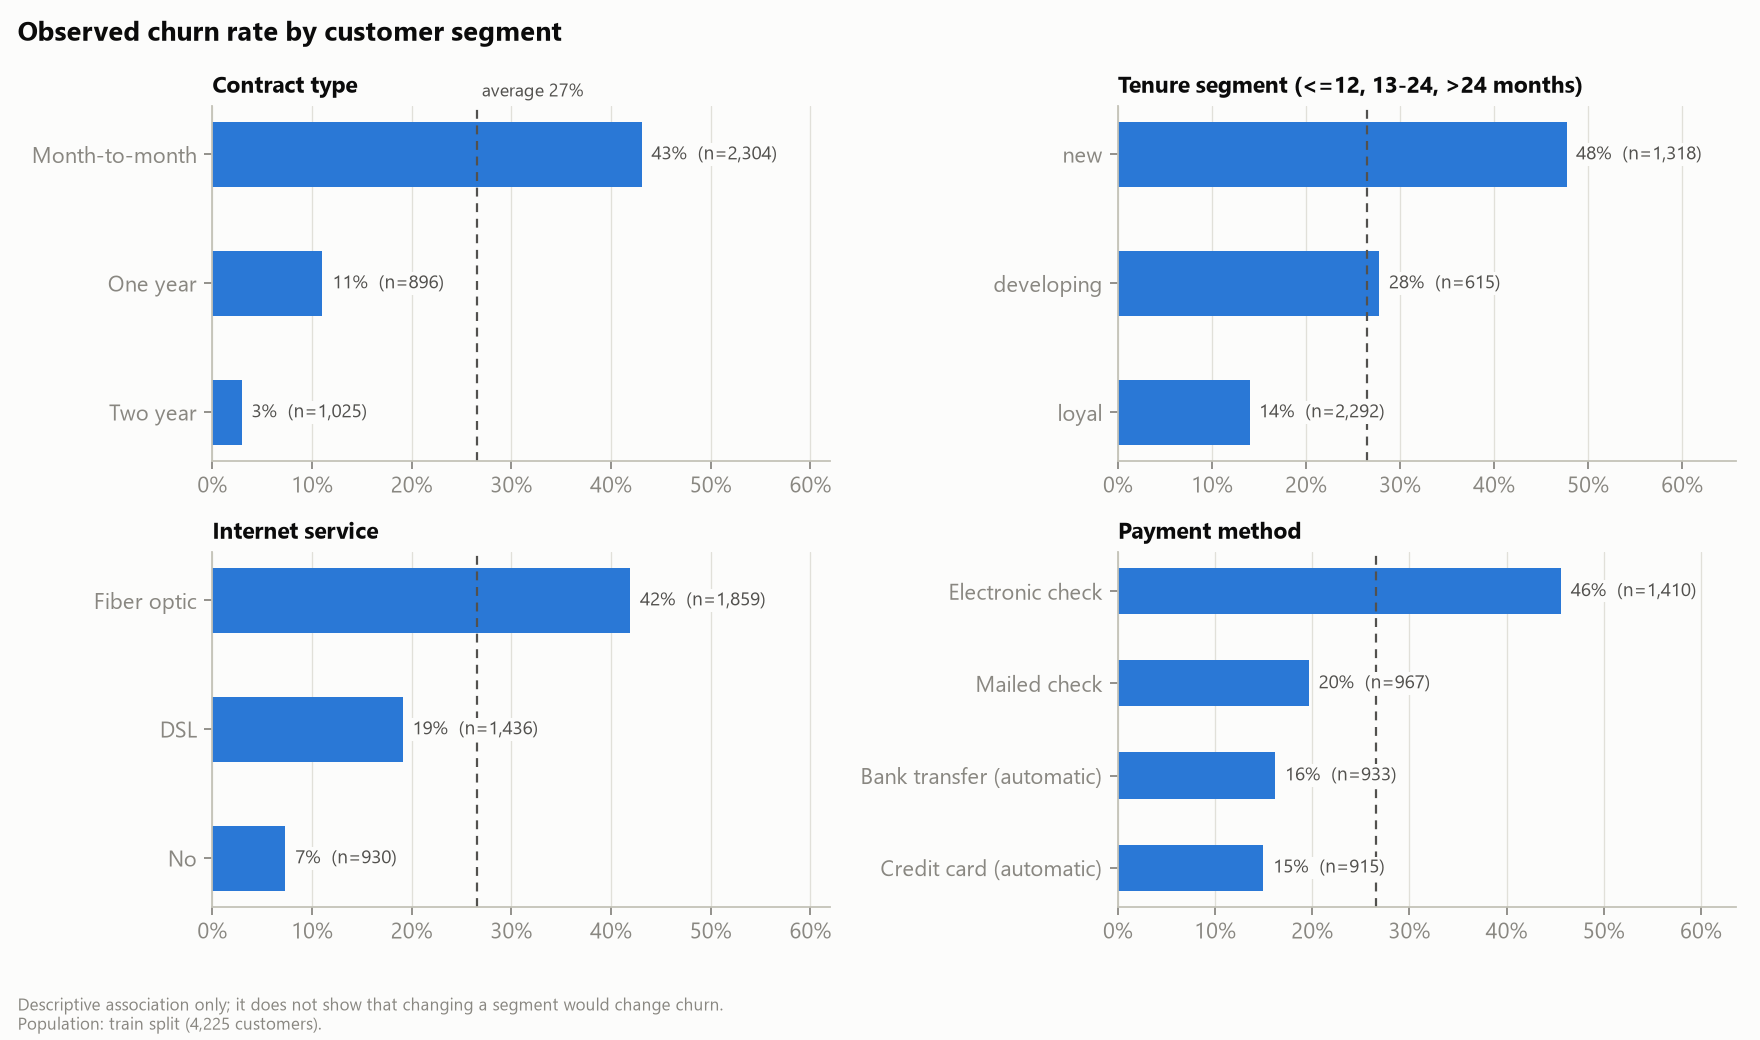

In [5]:
display(Image(filename=str(ROOT / "reports/figures/eda_drivers.png")))

**Interpretation.**
- **Contract:** Month-to-month churn 43% vs Two year 3% (n = 2,304 and 1,025).
- **tenure_segment:** new churn 48% vs loyal 14% (n = 1,318 and 2,292).
- **InternetService:** Fiber optic churn 42% vs No 7% (n = 1,859 and 930).
- **PaymentMethod:** Electronic check churn 46% vs Credit card (automatic) 15% (n = 1,410 and 915).

These are associations, not causes: moving a customer to a longer contract would not necessarily change their churn. They still guide offer design: the catalog includes a contract-upgrade credit for month-to-month customers and a service bundle for internet customers without technical support.

## Risk and value are different things

High churn does not mean high value. New, month-to-month customers churn most but often pay less and have shorter expected remaining tenure; long-tenure customers churn less but are worth more. The next notebooks turn this into numbers: a calibrated churn probability and a value proxy, combined into expected value.

In [6]:
train = customers.query("split == 'train'")
profile = train.assign(tenure_segment=pd.cut(train.tenure, [-1, 12, 24, 100], labels=["new", "developing", "loyal"])).groupby("tenure_segment", observed=True).agg(
    customers=("churn", "size"), churn_rate=("churn", "mean"), mean_monthly_charges=("MonthlyCharges", "mean"))
display(profile)

,customers,churn_rate,mean_monthly_charges
tenure_segment,,,
new,1318,0.477,56.492
developing,615,0.278,60.427
loyal,2292,0.140,70.925


**So what.** A rule that only follows churn risk would concentrate on new, low-value customers. The decision needs both dimensions, which is what the expected-value rule in notebook 3 does.

## Why customers leave (IBM extended sample)

IBM's extended version of the same customers records a reason for every churner. The join is accepted only because every customer ID and seven shared fields match; reasons are recorded after customers left, so they are kept in a separate file and never become model inputs.

{'joined_on': 'customerID = CustomerID', 'base_rows': 7043, 'matched': 7043, 'field_agreement': {'Churn': 1.0, 'tenure': 1.0, 'MonthlyCharges': 1.0, 'Contract': 1.0, 'InternetService': 1.0, 'PaymentMethod': 1.0, 'TechSupport': 1.0}, 'kept_fields': ['Churn Reason', 'CLTV'], 'dropped_fields': 'Churn Score, location and all other columns', 'accepted': True}


,churn_category,churn_reason,churners,population,share,addressable_by_offer
1,Attitude,Attitude of support person,192,all churners,0.103,False
4,Competitor,Competitor offered higher download speeds,189,all churners,0.101,True
5,Competitor,Competitor offered more data,162,all churners,0.087,True
14,Other,Don't know,154,all churners,0.082,False
3,Competitor,Competitor made better offer,140,all churners,0.075,True
0,Attitude,Attitude of service provider,135,all churners,0.072,False
2,Competitor,Competitor had better devices,130,all churners,0.070,True
8,Dissatisfaction,Network reliability,103,all churners,0.055,False
11,Dissatisfaction,Product dissatisfaction,102,all churners,0.055,False
19,Price,Price too high,98,all churners,0.052,True


,attribute,group,churners,Competitor,Dissatisfaction,Attitude,Price,Other,max_gap_to_overall
0,InternetService,DSL,459,0.325,0.272,0.153,0.113,0.137,0.024
1,InternetService,Fiber optic,1297,0.336,0.241,0.180,0.134,0.109,0.008
2,InternetService,No,113,0.319,0.248,0.204,0.150,0.080,0.034
3,Contract,Month-to-month,1655,0.328,0.253,0.175,0.130,0.115,0.004
4,Contract,One year,166,0.355,0.211,0.199,0.102,0.133,0.038
5,Contract,Two year,48,0.396,0.250,0.104,0.229,0.021,0.099
6,tenure_segment,developing,294,0.320,0.259,0.194,0.102,0.126,0.028
7,tenure_segment,loyal,538,0.323,0.240,0.167,0.152,0.117,0.022
8,tenure_segment,new,1037,0.340,0.251,0.174,0.126,0.109,0.008


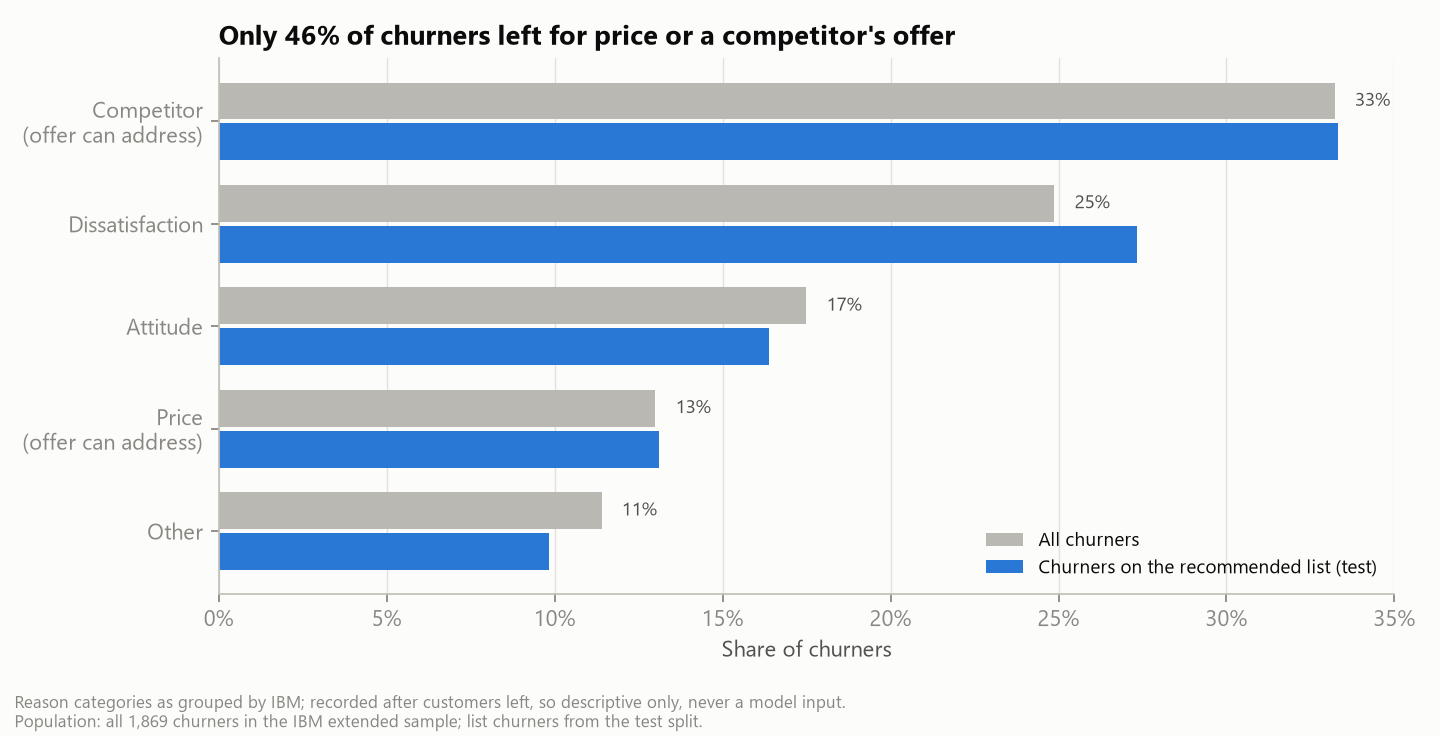

In [7]:
print(read_json(run / "extended_join.json"))
display(pd.read_csv(run / "churn_reasons.csv").query("population == 'all churners'").sort_values("churners", ascending=False).head(10))
display(pd.read_csv(run / "churn_reasons_by_segment.csv").round(3))
display(Image(filename=str(ROOT / "reports/figures/churn_reasons.png")))

**So what.** Only 46% of churners left for price or a competitor's offer, the reasons a discount or contract offer can address; 42% left over staff attitude or dissatisfaction. The mix barely differs by segment (largest gap 4 points), so in this sample the reasons bound what offers can achieve rather than telling us which offer to give whom.